# 🚀 DuneAI 2.5D - Huấn Luyện & Đánh Giá 3D Trên Google Colab

Notebook này được cấu hình chuẩn theo cấu trúc thư mục thực tế của dự án (**`data/` nằm ngang hàng với `DuneAI_Remake/`**):
```text
<WORKSPACE_DIR>/                     (VD: /content/drive/MyDrive/CT208E/SOURCES)
├── data/
│   └── cache_1mm/                   <-- Chứa slices.csv và các thư mục bệnh nhân (.npy)
├── checkpoints/                     <-- Lưu best_model.pth, last_model.pth, history.csv trên Drive
└── DuneAI_Remake/
    ├── configs/
    │   └── config.py
    ├── src/
    │   ├── models/
    │   │   ├── custom_backbone.py
    │   │   └── dune_unet.py
    │   ├── dataset.py
    │   ├── losses.py
    │   ├── medical_prep.py
    │   ├── offline_builder.py
    │   ├── postprocess.py
    │   └── trainer.py
    └── train_main.py
```

### ✨ Tính năng tích hợp:
1. **Hai chế độ nạp mã nguồn**: Mặc định chạy trực tiếp từ **Google Drive** (`USE_GITHUB = False`), đồng thời tích hợp sẵn cơ chế `git clone` / `git pull` từ **GitHub** (`USE_GITHUB = True`) khi bạn cần dùng sau này.
2. **Tăng tốc I/O trên Colab**: Tùy chọn copy `data/cache_1mm` từ Drive sang ổ cứng SSD cục bộ của máy ảo Colab (`/content/cache_1mm`) giúp tốc độ nạp batch nhanh gấp 5–10 lần, trong khi `checkpoints` vẫn lưu trực tiếp trên Google Drive.
3. **Tự động Resume (`--resume auto`)**: Nếu Colab bị ngắt kết nối giữa chừng, chỉ cần bấm **Run all** lại từ đầu, hệ thống sẽ tự động khôi phục từ `last_model.pth` và chạy tiếp Epoch đang dở.

## 1. Kết Nối Google Drive & Cấu Hình Đường Dẫn (Drive / GitHub)
Chỉnh lại biến `WORKSPACE_DRIVE_DIR` bên dưới cho khớp với đường dẫn thư mục chứa `data/` và `DuneAI_Remake/` trên Google Drive của bạn.

In [2]:
from google.colab import drive
import os
import subprocess
from pathlib import Path

# 1. Mount Google Drive
drive.mount('/content/drive')

# ======================================================================
# CẤU HÌNH ĐƯỜNG DẪN GỐC TRÊN GOOGLE DRIVE (Nơi chứa cả data/ và DuneAI_Remake/)
# ======================================================================
WORKSPACE_DRIVE_DIR = Path('/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES')

# ======================================================================
# CHẾ ĐỘ NGUỒN CODE: False = Dùng code trên Drive | True = Lấy từ GitHub
# ======================================================================
USE_GITHUB = False
GITHUB_REPO_URL = 'https://github.com/NguyenMinhTri24072005/DuneAI_Remake.git'  # Thay URL repo của bạn khi bật USE_GITHUB
GITHUB_BRANCH = 'main'

# Thiết lập đường dẫn data và checkpoints (Luôn nằm trên Drive để bảo toàn dữ liệu)
DRIVE_DATA_DIR = WORKSPACE_DRIVE_DIR / 'data' / 'cache_1mm'
SAVE_DIR = WORKSPACE_DRIVE_DIR / 'checkpoints' / 'dune_unet_25d'
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Thiết lập đường dẫn mã nguồn DuneAI_Remake
if not USE_GITHUB:
    CODE_DIR = WORKSPACE_DRIVE_DIR / 'DuneAI_Remake'
    print(f'📂 Chế độ DRIVE: Sử dụng mã nguồn tại {CODE_DIR}')
else:
    CODE_DIR = Path('/content/DuneAI_Remake')
    if not CODE_DIR.exists():
        print(f'🌐 Đang clone mã nguồn từ GitHub ({GITHUB_BRANCH})...')
        subprocess.run(['git', 'clone', '-b', GITHUB_BRANCH, GITHUB_REPO_URL, str(CODE_DIR)], check=True)
    else:
        print('🔄 Đang cập nhật mã nguồn mới nhất từ GitHub (git pull)...')
        subprocess.run(['git', '-C', str(CODE_DIR), 'pull'], check=True)

# Kiểm tra tính hợp lệ của cấu trúc thư mục
assert CODE_DIR.exists(), f'❌ Không tìm thấy thư mục code: {CODE_DIR}'
assert (CODE_DIR / 'train_main.py').exists(), f'❌ Không tìm thấy file {CODE_DIR / "train_main.py"}'
assert DRIVE_DATA_DIR.exists(), f'❌ Không tìm thấy thư mục dữ liệu: {DRIVE_DATA_DIR}'

# Đứng tại thư mục cha của DuneAI_Remake (hoặc trong DuneAI_Remake đều chạy được)
os.chdir(WORKSPACE_DRIVE_DIR if not USE_GITHUB else '/content')
print(f'✅ Thư mục làm việc hiện tại: {os.getcwd()}')
print(f'✅ Đường dẫn mã nguồn       : {CODE_DIR}')
print(f'✅ Đường dẫn cache_1mm (Drive): {DRIVE_DATA_DIR}')
print(f'✅ Đường dẫn lưu Checkpoints : {SAVE_DIR}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📂 Chế độ DRIVE: Sử dụng mã nguồn tại /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/DuneAI_Remake
✅ Thư mục làm việc hiện tại: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES
✅ Đường dẫn mã nguồn       : /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/DuneAI_Remake
✅ Đường dẫn cache_1mm (Drive): /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data/cache_1mm
✅ Đường dẫn lưu Checkpoints : /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/checkpoints/dune_unet_25d


## 2. Tăng Tốc Đọc Dữ Liệu Bằng SSD Cục Bộ Của Colab (Khuyên Dùng)
Việc đọc hàng ngàn lát cắt `.npy` qua Google Drive FUSE có thể bị nghẽn băng thông ở những epoch đầu. Khi để `COPY_CACHE_TO_LOCAL_SSD = True`, dữ liệu `cache_1mm` sẽ được chép sang ổ cứng NVMe cục bộ của máy ảo Colab (`/content/local_cache_1mm`), giúp GPU hoạt động 100% công suất.

In [3]:
import shutil
import time

COPY_CACHE_TO_LOCAL_SSD = True
LOCAL_CACHE_DIR = Path('/content/local_cache_1mm')

if COPY_CACHE_TO_LOCAL_SSD:
    t0 = time.time()
    LOCAL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
    print(f'⚡ Đang đồng bộ {DRIVE_DATA_DIR} -> {LOCAL_CACHE_DIR} (SSD Colab)...')
    !rsync -a --info=progress2 "{DRIVE_DATA_DIR}/" "{LOCAL_CACHE_DIR}/"
    ACTIVE_CACHE_DIR = LOCAL_CACHE_DIR
    print(f'✅ Đồng bộ hoàn tất trong {time.time() - t0:.1f}s! Đang dùng cache tốc độ cao tại: {ACTIVE_CACHE_DIR}')
else:
    ACTIVE_CACHE_DIR = DRIVE_DATA_DIR
    print(f'ℹ️ Đọc dữ liệu trực tiếp từ Google Drive: {ACTIVE_CACHE_DIR}')

⚡ Đang đồng bộ /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/data/cache_1mm -> /content/local_cache_1mm (SSD Colab)...
  2,677,204,614 100%   22.82MB/s    0:01:51 (xfr#101, to-chk=0/127)
✅ Đồng bộ hoàn tất trong 115.6s! Đang dùng cache tốc độ cao tại: /content/local_cache_1mm


## 3. Kiểm Tra GPU & Cài Đặt Thư Viện
Đảm bảo bạn đã bật GPU trong **Runtime > Change runtime type > T4 GPU**.

In [4]:
!nvidia-smi
!pip install -q pandas numpy opencv-python SimpleITK scipy tqdm scikit-image matplotlib

Wed Nov  4 17:28:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   33C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 4. Kiểm Thử Hệ Thống (Sanity Check) & Kiểm Tra Batch Dữ Liệu
Chạy kiểm thử tự động cho toàn bộ pipeline (`train_main.py`, `postprocess.py`) và kiểm tra thử 1 batch thực tế từ `cache_1mm`.

In [5]:
# 1. Chạy selftest của train_main.py và postprocess.py
!python "{CODE_DIR}/train_main.py" selftest
!python "{CODE_DIR}/src/postprocess.py" selftest

# 2. Nếu chưa có slices.csv thì tự động tạo
if not (ACTIVE_CACHE_DIR / 'slices.csv').exists():
    !python "{CODE_DIR}/src/offline_builder.py" build --cache-dir "{ACTIVE_CACHE_DIR}"

# 3. Kiểm tra 1 batch thực tế từ DataLoader
!python "{CODE_DIR}/src/dataset.py" inspect --cache-dir "{ACTIVE_CACHE_DIR}" --batch-size 4

Đang chạy kiểm thử toàn trình train_main.py (dữ liệu giả lập + Resume)...
📋 Chưa có slices.csv -> đang tạo chỉ mục...
📊 THỐNG KÊ CHỈ MỤC DỮ LIỆU (OFFLINE BUILDER)
Tổng số bệnh nhân : 4 (3 Train | 1 Val)
Tổng lát cắt giữ lại: 16 (12 Train | 4 Val)
  + Dương tính (Có u >= 20.0 mm²): 12
  + Âm tính (Không u, có phổi)       : 4
Các lát cắt đã lọc bỏ:
  - Không chứa nhu mô phổi           : 0
  - Khối u quá nhỏ (< 20.0 mm²)     : 0
  - Âm tính dư thừa (Negative Sample): 16
✅ Đã xuất bảng chỉ mục tại: /tmp/tmprvt2yb8r/cache/slices.csv
-----------------------------------------------------------------
  train:     12 lát |    3 bệnh nhân | có u: 9 | âm tính: 3
  val  :      4 lát |    1 bệnh nhân | có u: 3 | âm tính: 1
-----------------------------------------------------------------
📦 Số lát dùng thực tế: train=12 | val=4
🧠 DuneUNet(features=8) | 486,553 tham số | loss=dice_bce | lr=0.003 | scheduler=cosine | batch=4
ℹ️  Chế độ --resume auto: Chưa có '/tmp/tmprvt2yb8r/ckpt/last_model.pth', bắt

## 5. 🏃‍♂️ HUẤN LUYỆN CHÍNH THỨC (TRAINING + AUTO RESUME)
* **`--gpu-window`**: Đẩy ảnh `int16` lên GPU rồi chuẩn hóa cửa sổ HU trực tiếp bằng `window_hu_torch`.
* **`--resume auto`**: Tự động kiểm tra `<SAVE_DIR>/last_model.pth` trên Google Drive. Nếu Colab từng bị ngắt kết nối, mô hình sẽ tự động khôi phục đúng Epoch, Optimizer, Scheduler, Best Val Dice và nối tiếp `history.csv`.

In [6]:
EPOCHS = 50
BATCH_SIZE = 8
FEATURES = 64
LR = 1e-4
LOSS_TYPE = 'dice_bce'   # 'dice_bce' hoặc 'tversky'
SCHEDULER = 'cosine'     # 'cosine', 'plateau', hoặc 'none'
PATIENCE = 12            # Early stopping patience (0 = tắt)

!python "{CODE_DIR}/train_main.py" train \
  --cache-dir "{ACTIVE_CACHE_DIR}" \
  --save-dir "{SAVE_DIR}" \
  --epochs {EPOCHS} \
  --batch-size {BATCH_SIZE} \
  --features {FEATURES} \
  --lr {LR} \
  --loss {LOSS_TYPE} \
  --scheduler {SCHEDULER} \
  --patience {PATIENCE} \
  --workers 2 \
  --gpu-window \
  --resume auto

# Nếu dùng cache local và vừa tạo mới slices.csv, đồng bộ lại slices.csv về Drive
if COPY_CACHE_TO_LOCAL_SSD and (LOCAL_CACHE_DIR / 'slices.csv').exists() and not (DRIVE_DATA_DIR / 'slices.csv').exists():
    shutil.copy2(LOCAL_CACHE_DIR / 'slices.csv', DRIVE_DATA_DIR / 'slices.csv')

-----------------------------------------------------------------
  train:    320 lát |   21 bệnh nhân | có u: 254 | âm tính: 66
  val  :     50 lát |    4 bệnh nhân | có u: 40 | âm tính: 10
-----------------------------------------------------------------
📦 Số lát dùng thực tế: train=320 | val=50
🧠 DuneUNet(features=64) | 31,037,633 tham số | loss=dice_bce | lr=0.0001 | scheduler=cosine | batch=8
ℹ️  Chế độ --resume auto: Chưa có '/content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/checkpoints/dune_unet_25d/last_model.pth', bắt đầu huấn luyện mới từ Epoch 1.
🚀 BẮT ĐẦU HUẤN LUYỆN | Thiết bị: cuda | AMP: True | Epochs: 1 -> 50 | Batch: 40 train, 7 val
Epoch [01/50] | LR: 9.99e-05 | Train [Loss: 0.5001, Dice: 0.1497, IoU: 0.0809] | Val [Loss: 0.5056, Dice: 0.0653, IoU: 0.0338] | Time: 32.4s (Tr:30.5s/Va:1.9s) | ETA: 26m 26s ⭐ [BEST]
Epoch [02/50] | LR: 9.96e-05 | Train [Loss: 0.4824, Dice: 0.2718, IoU: 0.1573] | Val [Loss: 0.4906, Dice: 0.1976, IoU: 0.1096] | Time

## 6. 📈 Biểu Đồ Quá Trình Huấn Luyện (`history.csv`)
Trực quan hóa đường cong hội tụ của `Train/Val Loss` và `Train/Val Dice, IoU` qua các Epoch.

,epoch,lr,train_loss,train_dice,train_iou,val_loss,val_dice,val_iou,train_time_sec,val_time_sec,time_sec,eta_sec
21,22,0.000060,0.24767,0.80035,0.66715,0.44465,0.27536,0.15966,34.31,1.91,36.22,1006.54
22,23,0.000057,0.22951,0.80792,0.67774,0.39967,0.46381,0.30193,33.69,1.93,35.62,967.85
23,24,0.000054,0.23021,0.80267,0.67038,0.43151,0.30561,0.18037,34.26,1.90,36.17,933.55
24,25,0.000050,0.21323,0.81621,0.68948,0.41180,0.42798,0.27225,33.94,1.94,35.88,896.36
25,26,0.000047,0.21134,0.83355,0.71461,0.40156,0.38730,0.24015,34.21,1.94,36.15,864.17
26,27,0.000044,0.19425,0.84172,0.72669,0.41647,0.31005,0.18346,33.89,1.95,35.84,826.41
27,28,0.000041,0.19560,0.83326,0.71418,0.38310,0.42571,0.27042,34.21,1.92,36.13,792.69
28,29,0.000038,0.19391,0.84053,0.72492,0.42032,0.30914,0.18283,33.61,2.08,35.68,754.64
29,30,0.000035,0.19372,0.83994,0.72405,0.38640,0.39638,0.24718,34.03,1.93,35.96,719.02
30,31,0.000032,0.18297,0.84507,0.73170,0.36609,0.47233,0.30918,33.84,2.04,35.88,682.05


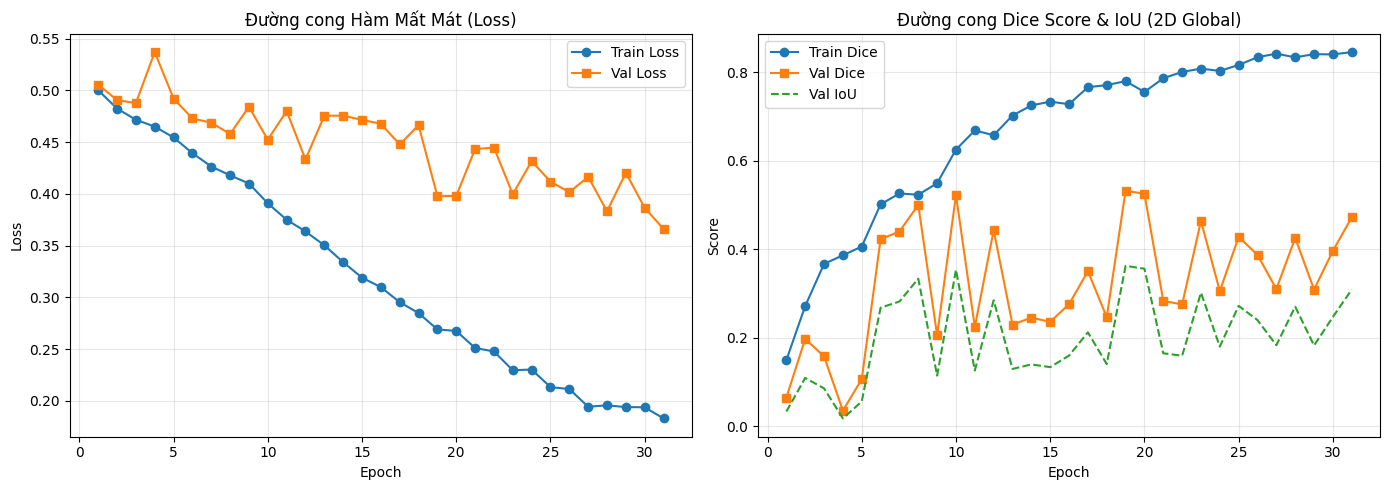

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

hist_path = SAVE_DIR / 'history.csv'
if hist_path.exists():
    df_hist = pd.read_csv(hist_path)
    display(df_hist.tail(10))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(df_hist['epoch'], df_hist['train_loss'], label='Train Loss', marker='o')
    axes[0].plot(df_hist['epoch'], df_hist['val_loss'], label='Val Loss', marker='s')
    axes[0].set_title('Đường cong Hàm Mất Mát (Loss)')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    axes[1].plot(df_hist['epoch'], df_hist['train_dice'], label='Train Dice', marker='o')
    axes[1].plot(df_hist['epoch'], df_hist['val_dice'], label='Val Dice', marker='s')
    axes[1].plot(df_hist['epoch'], df_hist['val_iou'], label='Val IoU', linestyle='--')
    axes[1].set_title('Đường cong Dice Score & IoU (2D Global)')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Score')
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(SAVE_DIR / 'training_curves.png', dpi=150)
    plt.show()
else:
    print(f'⚠️ Chưa tìm thấy {hist_path}')

## 7. 🩻 Đánh Giá Hậu Xử Lý 3D Cấp Độ Bệnh Nhân (`postprocess.py eval`)
Sau khi có `best_model.pth`, chạy suy luận 2.5D toàn khối + lọc hình thái học 3D để tính **Patient-level 3D Dice, 3D IoU và HD95 (mm)** trên tập Validation.

In [8]:
!python "{CODE_DIR}/src/postprocess.py" eval \
  --cache-dir "{ACTIVE_CACHE_DIR}" \
  --checkpoint "{SAVE_DIR}/best_model.pth" \
  --split val \
  --batch-size 16 \
  --threshold 0.5 \
  --tta \
  --out-csv "{SAVE_DIR}/eval_3d_results.csv"

🩻 ĐÁNH GIÁ 3D CẤP ĐỘ BỆNH NHÂN | Split: val (4 ca) | Thiết bị: cuda | Ngưỡng lọc u: >= 20.0 mm²
[01/04] LIDC-IDRI-0010 (41.4s) | 3D Dice: 0.0000 -> 0.0000 (+0.0000) | IoU: 0.0000 | HD95: 166.863 mm | Vol(GT/Pred): 347.5/2426.25 mm³
[02/04] LIDC-IDRI-0013 (13.7s) | 3D Dice: 0.2541 -> 0.2566 (+0.0025) | IoU: 0.1472 | HD95: 104.994 mm | Vol(GT/Pred): 2845.0/14265.0 mm³
[03/04] LIDC-IDRI-0017 (28.6s) | 3D Dice: 0.0000 -> 0.0000 (+0.0000) | IoU: 0.0000 | HD95: 179.176 mm | Vol(GT/Pred): 168.75/6561.25 mm³
[04/04] LIDC-IDRI-0020 (28.1s) | 3D Dice: 0.4469 -> 0.4493 (+0.0024) | IoU: 0.2897 | HD95: 138.24 mm | Vol(GT/Pred): 4108.75/4983.75 mm³
📊 TỔNG KẾT (4 bệnh nhân) | Mean 3D Dice (Raw): 0.1753 -> Mean 3D Dice (Post): 0.1765 (+0.0012) | Mean 3D IoU: 0.1092
✅ Đã lưu bảng báo cáo đánh giá 3D tại: /content/drive/MyDrive/COMPUTER SCIENCE/NAM4_HK1_(2026-2027)/CT208E/SOURCES/checkpoints/dune_unet_25d/eval_3d_results.csv
